## Setup (Dependencies & Environment)
### **Install** :
openai
python-dotenv
iykernel
### **Environment**:
Set `OPENAI_API_KEY` in your shell or create a `.env` file in the same folder (this notebook calls `load_dotenv(override=True)`).

Example `.env`:

```bash
OPENAI_API_KEY=your_key_here
```


In [ ]:
# Setup
!pip install -q openai python-dotenv ipykernel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 18.4 MB/s eta 0:00:00


## 1) Load environment variables - Please read instructions carefully

In [ ]:
# if you are running in local, uncomment below line. also make sure you shall have a .env file
# import os
# load_dotenv()

In [1]:
# if you are running in google colab, getpass() to securely enter the API key without displaying it.
import os
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from openai import OpenAI
from sklearn.decomposition import PCA

# Ensure the API key is always prompted by clearing it if already set
if "OPENAI_API_KEY" in os.environ:
    del os.environ["OPENAI_API_KEY"]

if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("Enter your OpenAI API key: ")

client = OpenAI()
MODEL = "text-embedding-3-small"

print("OpenAI client is ready.")

Enter your OpenAI API key: ··········
OpenAI client is ready.


# Embeddings

This notebook demonstrates semantic closeness using cosine similarity.
Words with similar meanings should have higher similarity scores than unrelated ones.


## Getting embeddings

In [2]:
response = client.embeddings.create(
    input="Your text string goes here",
    model="text-embedding-3-small"
)

print(response.data[0].embedding)

[0.005130767822265625, 0.0171966552734375, -0.0187225341796875, -0.0185546875, -0.047271728515625, -0.030303955078125, 0.027679443359375, 0.0036640167236328125, 0.01123809814453125, 0.00641632080078125, -0.00168609619140625, 0.0158233642578125, -0.0012884140014648438, -0.0078125, 0.05987548828125, 0.050262451171875, -0.0274658203125, 0.009918212890625, -0.04034423828125, 0.049957275390625, -0.0004527568817138672, 0.03021240234375, -0.01372528076171875, 0.03289794921875, 0.017303466796875, 0.01678466796875, -0.0017557144165039062, 0.020416259765625, 0.040771484375, -0.037750244140625, -0.026092529296875, -0.04998779296875, 0.024139404296875, -0.05517578125, -0.0322265625, 0.042388916015625, 0.064697265625, 0.01471710205078125, -0.0156402587890625, -0.04132080078125, 0.02215576171875, 0.007335662841796875, 0.044891357421875, 0.007068634033203125, -0.0240936279296875, 0.052398681640625, -0.02008056640625, -0.03216552734375, 0.0162200927734375, 0.046478271484375, 0.0238494873046875, -0.018

In [3]:
# Dimension
len(response.data[0].embedding)

1536

## Discussion:

What happens if we change the dimenstion of embedding vector?

Solution: same input + model + dimension, normally the same embedding vector
change the dimension, the embedding vector changes.
Dimension = 100 is not simply taking the first 100 of a 1536 vector.

In [5]:
response = client.embeddings.create(
    input="Your text string goes here",
    model="text-embedding-3-small",
    dimensions=100
)

print(response.data[0].embedding)
print(len(response.data[0].embedding))

[0.0178375244140625, 0.06011962890625, -0.06536865234375, -0.064697265625, -0.1646728515625, -0.1055908203125, 0.096435546875, 0.0127105712890625, 0.039215087890625, 0.0223236083984375, -0.005847930908203125, 0.055145263671875, -0.00437164306640625, -0.0273284912109375, 0.2088623046875, 0.17529296875, -0.095947265625, 0.034637451171875, -0.140625, 0.17431640625, -0.0015010833740234375, 0.10516357421875, -0.04779052734375, 0.1148681640625, 0.06036376953125, 0.058563232421875, -0.006122589111328125, 0.07135009765625, 0.1422119140625, -0.1314697265625, -0.09112548828125, -0.17431640625, 0.08428955078125, -0.1925048828125, -0.1123046875, 0.1475830078125, 0.2254638671875, 0.05133056640625, -0.054656982421875, -0.1441650390625, 0.07720947265625, 0.0258331298828125, 0.1566162109375, 0.02471923828125, -0.083984375, 0.1826171875, -0.07000732421875, -0.1123046875, 0.056732177734375, 0.1619873046875, 0.08306884765625, -0.065673828125, -0.0185394287109375, 0.1533203125, -0.021514892578125, 0.02534

In [6]:
# Embeddings API can accept multiple input texts at once
response = client.embeddings.create(
    input=["Your text string goes here",
           "what is the annual leave policy",
           "How do I submit an expense claim?"
    ],
    model="text-embedding-3-small"
)
# Embedding result for the first text
print(response.data[0].embedding)

# Embedding result for the first text
print(response.data[1].embedding)

[0.00518035888671875, 0.0172119140625, -0.0186920166015625, -0.0185699462890625, -0.047271728515625, -0.030303955078125, 0.027679443359375, 0.00365447998046875, 0.011260986328125, 0.006404876708984375, -0.0016956329345703125, 0.015838623046875, -0.001300811767578125, -0.0078582763671875, 0.0599365234375, 0.05029296875, -0.0275115966796875, 0.00992584228515625, -0.040374755859375, 0.050048828125, -0.00041413307189941406, 0.030242919921875, -0.01373291015625, 0.03289794921875, 0.017333984375, 0.01678466796875, -0.0017604827880859375, 0.02044677734375, 0.040802001953125, -0.0377197265625, -0.0261688232421875, -0.050048828125, 0.024200439453125, -0.055206298828125, -0.032257080078125, 0.042388916015625, 0.06475830078125, 0.01470184326171875, -0.0156402587890625, -0.041351318359375, 0.0221710205078125, 0.00737762451171875, 0.044921875, 0.00708770751953125, -0.0240631103515625, 0.05242919921875, -0.0201263427734375, -0.0322265625, 0.016265869140625, 0.046478271484375, 0.0238494873046875, -0.

In [7]:
len(response.data[0].embedding)


1536

In [8]:
# for multiple inputs
embeddings = np.array(
    [item.embedding for item in response.data]
)
embeddings.shape


(3, 1536)

## Cosine similarity

Cosine similarity measures how close two vectors are in direction (ignoring magnitude).
A score of **1.0** means identical direction, **0** means orthogonal, and **−1** means opposite.

In [9]:
import math

def cosine_similarity(a, b):
    dot = sum(x * y for x, y in zip(a, b))
    norm_a = math.sqrt(sum(x * x for x in a))
    norm_b = math.sqrt(sum(x * x for x in b))
    return dot / (norm_a * norm_b) if norm_a and norm_b else 0.0

In [ ]:
# Quick sanity check with simple 2D vectors
cosine_similarity([1, 0], [1, 0])
# cosine_similarity([1, 0], [-1, 0])
#cosine_similarity([1, 0], [0, 1])
#cosine_similarity([1, 0], [1, 1])

1.0

## Comparing word embeddings

Let's embed a set of words and see how cosine similarity captures semantic relationships.

In [10]:
words = [
    "cat", "dog", "kitten", "puppy",
    "car", "automobile",
    "banana", "apple",
    "king", "queen", "man", "woman",
    "Paris", "France", "Tokyo", "Japan", "Singapore",
]

response = client.embeddings.create(
    model="text-embedding-3-small",
    input=words,
)

embedding_by_word = {
    word: response.data[i].embedding
    for i, word in enumerate(words)
}

In [11]:
pairs = [
    ("cat", "dog"),
    ("kitten", "puppy"),
    ("car", "automobile"),
    ("king", "queen"),
    ("man", "woman"),
    ("Paris", "France"),
    ("Paris", "Singapore"),
    ("Tokyo", "Japan"),
    ("banana", "apple"),
    ("cat", "banana"),
    ("car", "king"),
    ("Paris", "puppy"),
    ("queen", "automobile"),
]

print("Cosine similarity (higher = more similar):\n")
for a, b in pairs:
    score = cosine_similarity(embedding_by_word[a], embedding_by_word[b])
    print(f"  {a:<12} {b:<12} {score:.3f}")

Cosine similarity (higher = more similar):

  cat          dog          0.603
  kitten       puppy        0.650
  car          automobile   0.556
  king         queen        0.591
  man          woman        0.707
  Paris        France       0.661
  Paris        Singapore    0.399
  Tokyo        Japan        0.471
  banana       apple        0.464
  cat          banana       0.298
  car          king         0.331
  Paris        puppy        0.204
  queen        automobile   0.219


## Visualize semantic relationship

Original embedding shape: (17, 1536)
PCA shape: (17, 2)


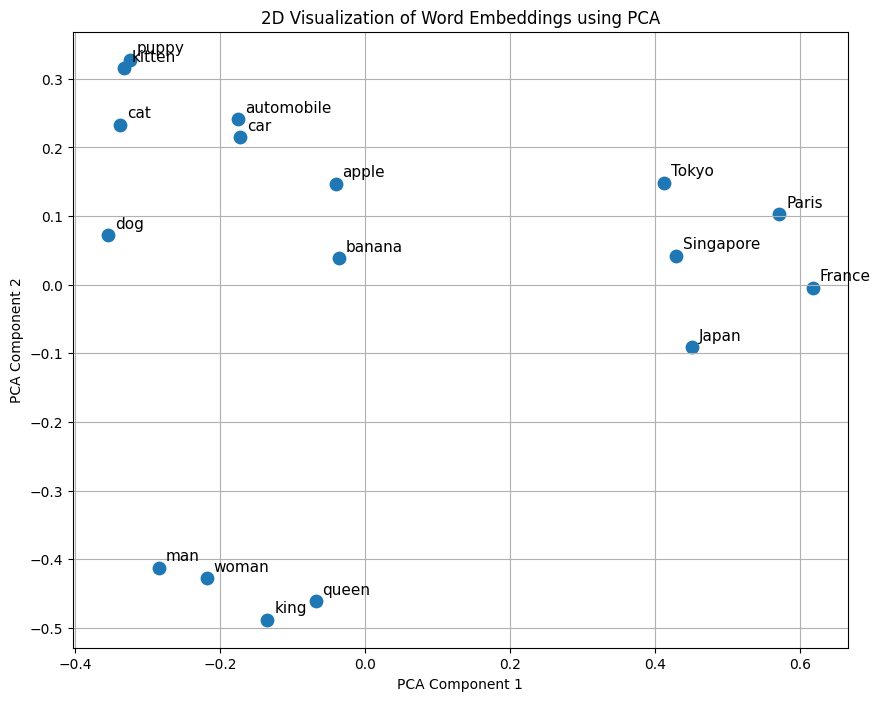

In [12]:
# 1. Get all unique words
words = sorted(set(word for pair in pairs for word in pair))

# 2. Get their embedding vectors
X = np.array([embedding_by_word[word] for word in words])

print("Original embedding shape:", X.shape)

# 3. Reduce embeddings to 2 dimensions using PCA
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

print("PCA shape:", X_2d.shape)

# 4. Plot
plt.figure(figsize=(10, 8))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    s=80
)

# Add word labels
for i, word in enumerate(words):
    plt.annotate(
        word,
        (X_2d[i, 0], X_2d[i, 1]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=11
    )

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("2D Visualization of Word Embeddings using PCA")
plt.grid(True)

plt.show()

The end.